<a href="https://colab.research.google.com/github/dapenuela/FP_Growth_Distribucion_Tienda/blob/main/FP_Growth_Distribucion_Tienda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Distribución estratégica de productos con FP-Growth
**Diego Armando Peñuela Cárdenas · Especialización en Inteligencia Artificial · Universidad de Cundinamarca**

Este notebook descubre co-compras, verifica su estabilidad en un periodo posterior y genera propuestas de exhibición. La demostración usa datos sintéticos y está lista para ejecutar en CPU.

Las reglas orientan cambios que deben revisarse contra el plano, inventario y restricciones de operación. La permanencia y las ventas se evalúan por separado en un piloto.

In [ ]:
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('mlxtend') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'mlxtend'])

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import fpgrowth, association_rules


## 1. Configuración y fuente de datos
Deja `CSV_PROPIO = False` para ejecutar la demostración. Si lo cambias a `True` en Colab aparecerá el selector de archivos. El CSV debe tener una fila por línea de ticket y las columnas `tienda,ticket,fecha,sku,cantidad`. Usa fechas ISO (`AAAA-MM-DD` o con hora), separador coma y cantidades positivas para ventas. Excluye tickets cancelados antes de exportar. Si existe una columna `es_devolucion`, se excluyen filas marcadas con `1`, `true`, `sí` o `si`. Una combinación tienda–ticket identifica una compra y el ejemplo supone que esa combinación no se reutiliza.

In [ ]:
CSV_PROPIO = False
MIN_SOPORTE = 0.02
MIN_COCOMPRAS = 30
MIN_CONFIANZA = 0.30
MIN_LIFT = 1.20
OUT = Path('salidas_tienda')
OUT.mkdir(exist_ok=True)

def crear_demo(semilla=42):
    rng = np.random.default_rng(semilla)
    grupos = [
        ['Pasta', 'Salsa', 'Queso'],
        ['Café', 'Galletas'],
        ['Pan', 'Mermelada'],
        ['Arroz', 'Aceite'],
    ]
    productos = sorted({sku for grupo in grupos for sku in grupo} |
                       {'Leche', 'Agua', 'Fruta', 'Jabón', 'Yogur'})
    filas = []
    for dia in range(84):
        fecha = pd.Timestamp('2026-01-05') + pd.Timedelta(days=dia)
        for j in range(24):
            grupo = grupos[rng.integers(len(grupos))]
            canasta = {sku for sku in grupo if rng.random() < 0.80}
            canasta.update(rng.choice(productos, size=rng.integers(1, 4), replace=False))
            for sku in sorted(canasta):
                filas.append(('Demo', f'{dia:03d}-{j:02d}', fecha, sku, 1))
    return pd.DataFrame(filas, columns=['tienda','ticket','fecha','sku','cantidad'])

if CSV_PROPIO:
    from google.colab import files
    archivos = files.upload()
    if len(archivos) != 1:
        raise ValueError('Selecciona exactamente un CSV.')
    nombre = next(iter(archivos))
    ventas = pd.read_csv(nombre, dtype={'tienda':str,'ticket':str,'sku':str})
    tienda_demo = False
else:
    ventas = crear_demo()
    tienda_demo = True

print('Fuente:', 'tickets sintéticos' if tienda_demo else 'CSV cargado')
display(ventas.head())


Fuente: tickets sintéticos


,tienda,ticket,fecha,sku,cantidad
0,Demo,000-00,2026-01-05,Agua,1
1,Demo,000-00,2026-01-05,Arroz,1
2,Demo,000-00,2026-01-05,Leche,1
3,Demo,000-00,2026-01-05,Pasta,1
4,Demo,000-00,2026-01-05,Queso,1


## 2. Depuración y validación cronológica
Se descartan filas incompletas o inválidas, devoluciones y cantidades no positivas. Un SKU repetido en un ticket se cuenta una sola vez. Se usan las últimas cuatro semanas calendario observadas como periodo posterior; se requieren datos anteriores al corte para descubrir reglas.

In [ ]:
campos = ['tienda','ticket','fecha','sku','cantidad']
faltantes = set(campos) - set(ventas.columns)
if faltantes:
    raise ValueError(f'Faltan columnas: {sorted(faltantes)}')

v = ventas.copy()
for campo in ['tienda','ticket','sku']:
    v[campo] = v[campo].astype('string').str.strip().replace('', pd.NA)
v['fecha'] = pd.to_datetime(v['fecha'], format='mixed', errors='coerce', utc=True).dt.tz_localize(None)
v['cantidad'] = pd.to_numeric(v['cantidad'], errors='coerce')
if 'es_devolucion' in v:
    marca = v['es_devolucion'].astype('string').str.strip().str.lower()
    v = v[~marca.isin(['1','1.0','true','sí','si'])]
v = v.dropna(subset=campos)
v = v[np.isfinite(v['cantidad']) & (v['cantidad'] > 0)]
if v.empty:
    raise ValueError('No quedaron líneas válidas.')
canastas = (v.groupby(['tienda','ticket'], as_index=False)
               .agg(fecha=('fecha','min'), items=('sku', lambda x: frozenset(x))))
corte = canastas['fecha'].max().normalize() - pd.Timedelta(days=27)
desc = canastas.loc[canastas['fecha'] < corte, 'items'].tolist()
val = canastas.loc[canastas['fecha'] >= corte, 'items'].tolist()
if not desc or not val:
    raise ValueError('El CSV debe cubrir más de cuatro semanas y tener tickets a ambos lados del corte.')
print(f'Corte: {corte.date()} | Descubrimiento: {len(desc)} | Validación: {len(val)}')


Corte: 2026-03-02 | Descubrimiento: 1344 | Validación: 672


## 3. Reglas FP-Growth y validación
Se extraen pares de productos. El soporte mide la proporción de canastas con ambos, la confianza mide la proporción de compras de B entre las compras de A y el lift contrasta esa confianza con la frecuencia base de B. El filtro inicial exige 2 % de soporte, 30 co-compras, 30 % de confianza y lift superior a 1,2. En el periodo posterior se pide el mismo soporte, confianza y lift, y se aplica un conteo mínimo proporcional al tamaño de la muestra con un piso de cinco tickets.

In [ ]:
from math import ceil

enc = TransactionEncoder()
mat = enc.fit(desc).transform(desc, sparse=True)
binaria = pd.DataFrame.sparse.from_spmatrix(mat, columns=enc.columns_)
soporte_efectivo = max(MIN_SOPORTE, MIN_COCOMPRAS / len(desc))
frecuentes = (fpgrowth(binaria, min_support=soporte_efectivo,
                       use_colnames=True, max_len=2)
              if soporte_efectivo <= 1 else pd.DataFrame())

columnas = ['producto_a','producto_b','soporte','confianza','lift','cocompras',
            'soporte_val','confianza_val','lift_val','cocompras_val','estable']
registros = []
min_val = max(5, ceil(MIN_COCOMPRAS * len(val) / len(desc)))
if not frecuentes.empty and frecuentes['itemsets'].map(len).max() >= 2:
    reglas = association_rules(frecuentes, metric='confidence', min_threshold=MIN_CONFIANZA)
    reglas = reglas[reglas['lift'] > MIN_LIFT]
    for _, regla in reglas.iterrows():
        a = next(iter(regla['antecedents']))
        b = next(iter(regla['consequents']))
        n_a = sum(a in cesta for cesta in val)
        n_b = sum(b in cesta for cesta in val)
        n_ab = sum(a in cesta and b in cesta for cesta in val)
        soporte = n_ab / len(val)
        confianza = n_ab / n_a if n_a else 0.0
        lift = confianza / (n_b / len(val)) if n_b else 0.0
        estable = (n_ab >= min_val and soporte >= MIN_SOPORTE and
                   confianza >= MIN_CONFIANZA and lift > MIN_LIFT)
        registros.append([a,b,regla['support'],regla['confidence'],regla['lift'],
                          round(regla['support']*len(desc)),soporte,confianza,lift,n_ab,estable])
evaluadas = pd.DataFrame(registros, columns=columnas).sort_values(
    ['estable','cocompras_val','lift_val'], ascending=False)
evaluadas.to_csv(OUT/'reglas_evaluadas.csv', index=False)
print(f'{len(evaluadas)} reglas dirigidas evaluadas | {int(evaluadas["estable"].sum())} estables.')
display(evaluadas.head(12).round(3))


12 reglas dirigidas evaluadas | 12 estables.


,producto_a,producto_b,soporte,confianza,lift,cocompras,soporte_val,confianza_val,lift_val,cocompras_val,estable
2,Aceite,Arroz,0.194,0.585,1.914,261,0.208,0.617,1.901,140,True
3,Arroz,Aceite,0.194,0.635,1.914,261,0.208,0.642,1.901,140,True
6,Pan,Mermelada,0.182,0.574,1.833,244,0.180,0.555,1.819,121,True
7,Mermelada,Pan,0.182,0.580,1.833,244,0.180,0.590,1.819,121,True
0,Pasta,Queso,0.196,0.584,1.822,263,0.177,0.604,2.040,119,True
1,Queso,Pasta,0.196,0.610,1.822,263,0.177,0.598,2.040,119,True
4,Café,Galletas,0.175,0.593,1.894,235,0.176,0.565,1.781,118,True
5,Galletas,Café,0.175,0.558,1.894,235,0.176,0.554,1.781,118,True
8,Pasta,Salsa,0.182,0.544,1.816,245,0.167,0.569,1.930,112,True
9,Salsa,Pasta,0.182,0.608,1.816,245,0.167,0.566,1.930,112,True


## 4. Propuestas de exhibición y piloto
Se conserva una fila por pareja para evitar recomendar la misma exhibición en ambos sentidos. Se priorizan parejas estables con más co-compras en el periodo posterior. La tabla deja las decisiones de ubicación y aprobación para operaciones. En una prueba con control, comparar ventas netas por visita y permanencia mediana, junto con conversión y espera en caja.

Exportaciones: parejas_estables.png, propuestas_exhibicion.csv, reglas_evaluadas.csv


,producto_a,producto_b,cocompras_val,lift_val,accion_sugerida
2,Aceite,Arroz,140,1.901,Evaluar exhibición conjunta o señalización
6,Pan,Mermelada,121,1.819,Evaluar exhibición conjunta o señalización
0,Pasta,Queso,119,2.040,Evaluar exhibición conjunta o señalización
4,Café,Galletas,118,1.781,Evaluar exhibición conjunta o señalización
8,Pasta,Salsa,112,1.930,Evaluar exhibición conjunta o señalización
10,Queso,Salsa,112,1.910,Evaluar exhibición conjunta o señalización


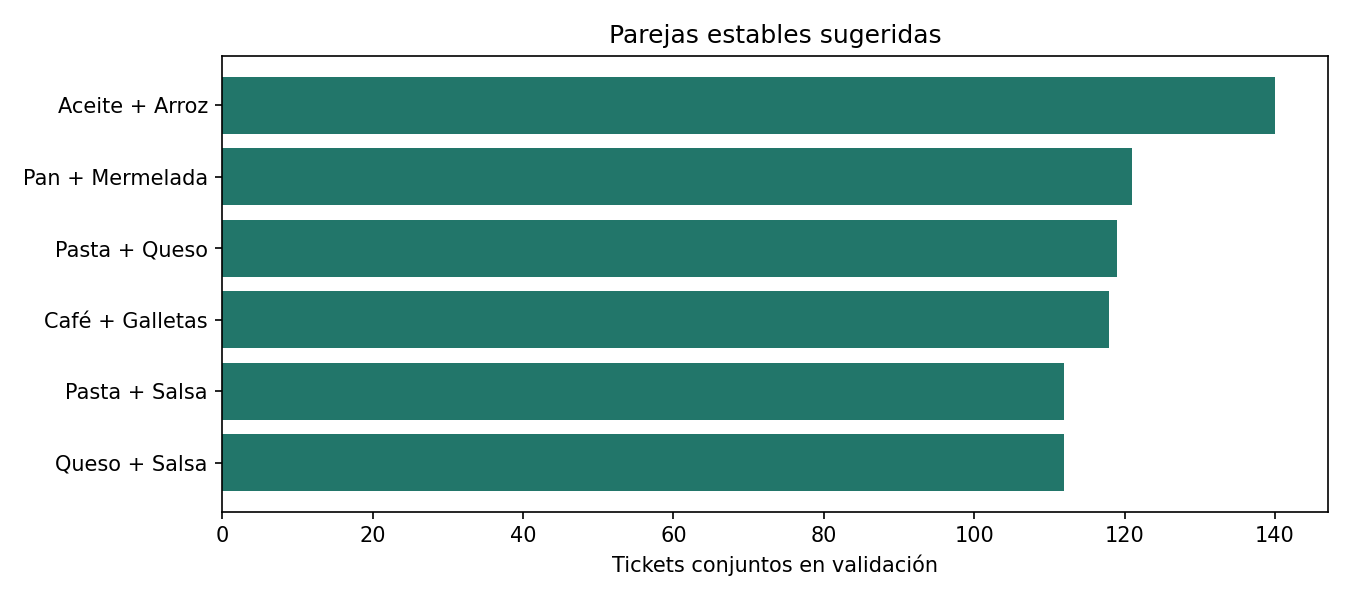

In [ ]:
propuestas = evaluadas.loc[evaluadas['estable']].copy()
propuestas['pareja'] = [tuple(sorted((a,b))) for a,b in
                         zip(propuestas['producto_a'], propuestas['producto_b'])]
propuestas = propuestas.drop_duplicates('pareja').drop(columns='pareja')
propuestas['accion_sugerida'] = 'Evaluar exhibición conjunta o señalización'
propuestas['zona_propuesta'] = ''
propuestas['aprobacion_operaciones'] = ''
propuestas.to_csv(OUT/'propuestas_exhibicion.csv', index=False)
display(propuestas[['producto_a','producto_b','cocompras_val','lift_val',
                    'accion_sugerida']].head(12).round(3))

if propuestas.empty:
    print('Sin parejas estables con estos datos y umbrales. Revisa volumen y calidad.')
else:
    vista = propuestas.head(8).iloc[::-1]
    plt.figure(figsize=(9, 4))
    plt.barh(vista['producto_a'] + ' + ' + vista['producto_b'],
             vista['cocompras_val'], color='#22766A')
    plt.xlabel('Tickets conjuntos en validación')
    plt.title('Parejas estables sugeridas')
    plt.tight_layout()
    plt.savefig(OUT/'parejas_estables.png', dpi=150)
    plt.show()

if tienda_demo:
    assert len(desc) == 1344 and len(val) == 672
    assert not propuestas.empty
    assert {'Pasta','Salsa'} in [set(p) for p in zip(propuestas.producto_a, propuestas.producto_b)]
print('Exportaciones:', ', '.join(sorted(p.name for p in OUT.iterdir())))


Los archivos quedan en `salidas_tienda/` y se pueden descargar desde el panel **Archivos** de Colab. Los datos de demostración prueban la ejecución del pipeline. La mejora comercial deberá medirse en tienda.

**Referencia.** Han, J., Pei, J., & Yin, Y. (2000). Mining frequent patterns without candidate generation. https://doi.org/10.1145/342009.335372